# COU 07506 Digital Signal Processing — Week 02: Lab 1A Sampling, Aliasing and Quantization
Name: Nickson Pascal Ngowi  Registration No 240242499465
Class: BENG24COE Group:06 Date: 25 November 2026
Instructor checkpoints signed: [ ] 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

## Pre-lab
(a) A 7 kHz tone sampled at 10 kHz: F_alias = |7 − 1×10| = **3 kHz**.
(b) Δ = 2·Xm / 2^B = 2 / 256 = **0.0078 V** (7.8 mV). SQNR = 6.02·8 + 1.76 = **49.9 dB**.

## Task 2.1 — Aliasing of a sinusoid

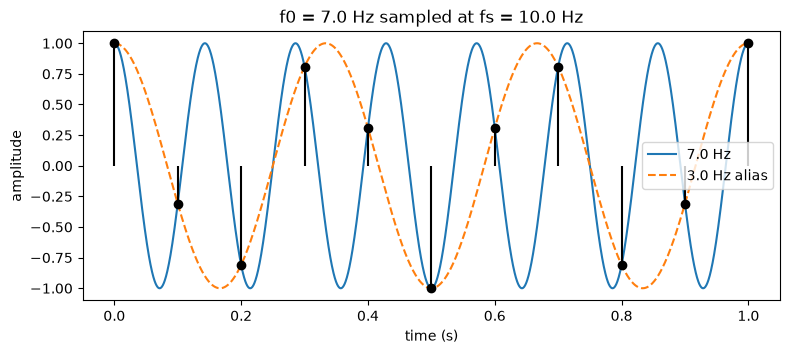

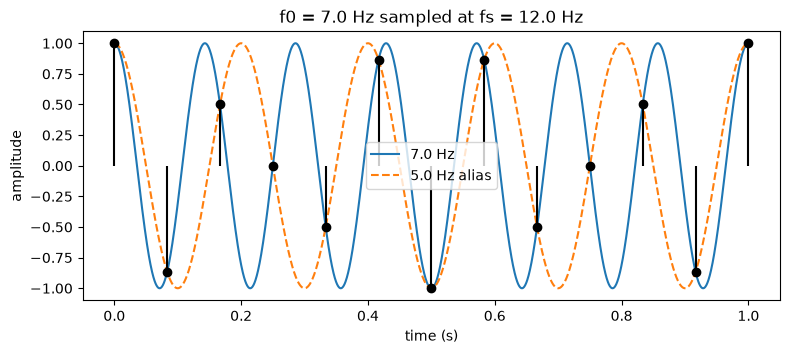

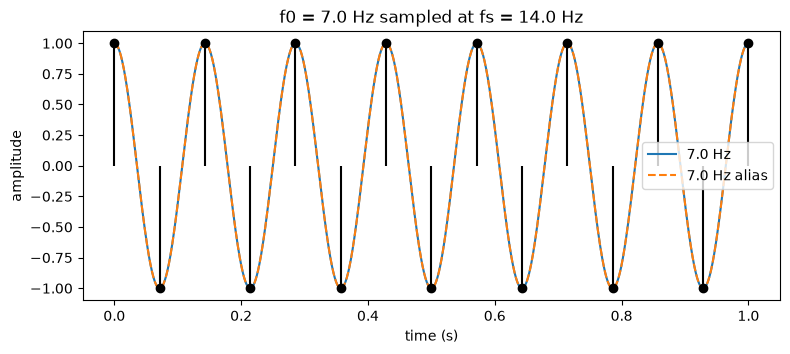

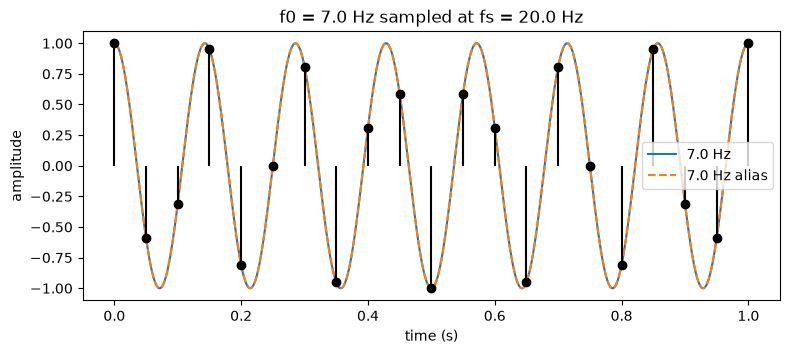

fs (Hz) | alias frequency (Hz)
    10  | 3.0
    12  | 5.0
    14  | 7.0
    20  | 7.0


In [2]:
def alias_demo(f0, fs):
    t = np.linspace(0, 1, 2000)
    n = np.arange(0, int(fs) + 1)
    tn = n / fs
    f_alias = abs(f0 - fs*round(f0/fs))
    plt.figure()
    plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0} Hz")
    plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias} Hz alias")
    plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ")
    plt.title(f"f0 = {f0} Hz sampled at fs = {fs} Hz")
    plt.xlabel("time (s)"); plt.ylabel("amplitude"); plt.legend(); plt.show()
    return f_alias

f0 = 7.0
rows = []
for fs_ in [10.0, 12.0, 14.0, 20.0]:
    rows.append((fs_, alias_demo(f0, fs_)))

print("fs (Hz) | alias frequency (Hz)")
for fs_, fa in rows:
    print(f"{fs_:6.0f}  | {fa:.1f}")

Alias table (f0 = 7 Hz, alias = |F − k·fs|):

| fs (Hz) | k | alias (Hz) | comment |
|---|---|---|---|
| 10 | 1 | 3 | 7 > fs/2 = 5, aliased |
| 12 | 1 | 5 | 7 > fs/2 = 6, aliased |
| 14 | 0 | 7 | fs/2 = 7, exactly at the limit, no folding |
| 20 | 0 | 7 | 7 < fs/2 = 10, no aliasing |

The values printed by the code agree with |F − k·fs|. Aliasing occurs only when fs < 2F.

## Task 2.2 — Hear aliasing

In [3]:
import os
fname = "my_voice.wav"
if os.path.exists(fname):
    fs, xv = wavfile.read(fname)
    xv = xv.mean(axis=1) if xv.ndim > 1 else xv.astype(float)
    xv = xv / np.max(np.abs(xv))
else:
    fs = 44100
    tt = np.arange(0, 3, 1/fs)
    xv = 0.5*signal.chirp(tt, 200, 3, 15000)

out = {}
for k in [2, 4, 8]:
    naive = xv[::k]
    proper = signal.decimate(xv, k, ftype="fir")
    out[k] = (naive, proper)
    print(k, "new fs =", fs // k, "Hz")

2 new fs = 22050 Hz
4 new fs = 11025 Hz
8 new fs = 5512 Hz


In [4]:
from IPython.display import Audio, display
k = 8
print("k = 8 naive (no filter):");   display(Audio(out[k][0], rate=fs//k))
print("k = 8 with anti-aliasing:");  display(Audio(out[k][1], rate=fs//k))

k = 8 naive (no filter):


k = 8 with anti-aliasing:


Listening observation for k = 8: the naive version (every 8th sample, no filter) sounds distorted and harsh, with extra false tones, because frequencies above the new Nyquist limit fold back into the audio band. The `signal.decimate` version sounds clean but duller/muffled, because the anti-aliasing filter removes the content above the new Nyquist frequency (fs/16).

## Task 2.3 — A uniform quantizer

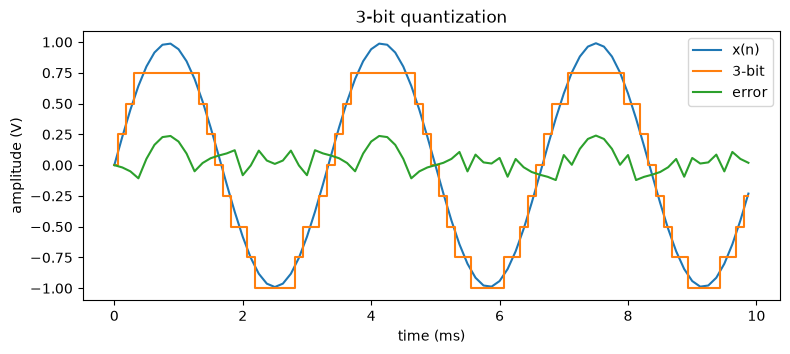

In [5]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs3 = 8000
t3 = np.arange(0, 0.01, 1/fs3)
xs = 0.99*np.sin(2*np.pi*300*t3)
xq = quantize(xs, 3)
plt.plot(t3*1e3, xs, label="x(n)")
plt.step(t3*1e3, xq, where="mid", label="3-bit")
plt.plot(t3*1e3, xs - xq, label="error")
plt.title("3-bit quantization"); plt.xlabel("time (ms)"); plt.ylabel("amplitude (V)")
plt.legend(); plt.show()

## Task 2.4 — Verify the 6 dB-per-bit rule

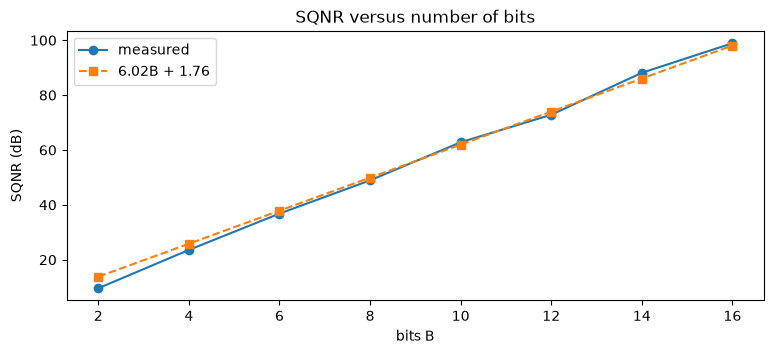

[ 9.6 23.6 36.8 48.9 62.8 72.8 88.1 98.9]


In [6]:
bits = np.arange(2, 17, 2)
meas = [10*np.log10(np.sum(xs**2)/np.sum((xs - quantize(xs, B))**2)) for B in bits]
plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, 6.02*bits + 1.76, "s--", label="6.02B + 1.76")
plt.title("SQNR versus number of bits")
plt.xlabel("bits B"); plt.ylabel("SQNR (dB)"); plt.legend(); plt.show()
print(np.round(meas, 1))

## Task 2.5 — Quantize your voice

In [7]:
for B in [4, 8, 12]:
    xq_v = quantize(xv, B)
    sqnr = 10*np.log10(np.sum(xv**2)/np.sum((xv - xq_v)**2))
    print(f"{B:2d} bits: SQNR = {sqnr:.1f} dB   (full-scale sine: {6.02*B+1.76:.1f} dB)")

 4 bits: SQNR = 20.4 dB   (full-scale sine: 25.8 dB)
 8 bits: SQNR = 44.0 dB   (full-scale sine: 49.9 dB)
12 bits: SQNR = 68.0 dB   (full-scale sine: 74.0 dB)


In [8]:
Audio(quantize(xv, 4), rate=fs)

Why is the SQNR of speech lower than for a full-scale sine? The quantization noise power (Δ²/12) depends only on the number of bits, but the signal power of speech is much lower than that of a full-scale sine. Speech has a high peak-to-RMS ratio (crest factor): it has rare loud peaks and is mostly quiet, so its average power is well below full scale. Less signal power with the same noise gives a lower SQNR than the 6.02B + 1.76 dB formula, which assumes a full-scale sine.

## Analysis questions
1. Sketch: on the frequency axis, mark the folding frequency fs/2 = 5 Hz. The 7 Hz tone is 2 Hz above 5 Hz, so it folds to 2 Hz below 5 Hz, which is 3 Hz. Equivalently, the sampled spectrum repeats every fs = 10 Hz, so 7 Hz looks like 7 − 10 = −3 Hz, which has the same samples as +3 Hz.
2. After sampling, the aliased tone and a genuine low-frequency tone give exactly the same sample values. The original information is lost, so no later processing can tell them apart. The anti-aliasing filter has to be applied before sampling or downsampling.
3. One extra bit halves Δ, which reduces the noise power by a factor of 4, so SQNR increases by about **6.02 dB**. My measured values (for B = 2, 4, 6, ...) increase by about 12 dB per two bits, so they agree with the 6 dB-per-bit rule.
4. The temperature changes by at most 0.1 °C/s, so it is a very slow signal. A sampling rate of 1 to 2 Hz is enough (10 Hz gives margin and allows averaging to reduce noise). Number of levels = 100 °C / 0.01 °C = 10 000. 2^13 = 8192 is not enough, but 2^14 = 16 384, so **14 bits** are needed.